# The Bayesian Workflow in PyMC

**What you'll learn**

- The full Bayesian workflow on one business problem — conversion across marketing
  channels whose volumes span three orders of magnitude — with each step as a first-class
  citizen: model specification, **prior predictive checks**, NUTS sampling, **convergence
  diagnostics** (R-hat, ESS, divergences, E-BFMI, trace plots), **posterior predictive
  checks**, and a decision.
- What a divergence actually is, why the centered hierarchical model produces hundreds of
  them on weak data (the funnel), and the non-centered reparameterization that fixes it —
  plus the senior twist: on data-rich groups the preference *flips*.
- Why "uninformative" priors on a logit scale are wildly informative on the probability
  scale, and how prior predictive simulation catches that before any data is touched.
- A side-by-side with the frequentist GLM: with flat priors and decent n the point
  estimates coincide — the payoff is the *full posterior on derived business quantities*
  (cost per acquisition, conversions per marginal dollar, P(best channel)).
- The small-data regime (n=20 per channel) where the MLE returns 0% conversion rates and
  perfectly separated GLMs, while a defensible informative prior returns sane answers.

**Why it matters in interviews**

- "Walk me through how you'd build and *check* a Bayesian model" is the standard senior
  screen for anyone who lists PyMC/Stan on a resume — the expected answer is this
  workflow, not a likelihood dump.
- "What are divergences and what do you do about them?" is the single most common
  Bayesian-computation question; the funnel + non-centering story is the canonical strong
  answer.
- "Why not just run a GLM?" probes whether you know what the posterior buys you *and*
  what it costs — the honest answer involves derived quantities, small data, and
  decisions, not ideology.
- Marketing/growth analytics roles love this exact setting: many channels, wildly unequal
  sample sizes, and a budget decision at the end.

We simulate the data so ground truth is known and every claim is checkable. Conjugate
closed-form Bayes (no sampler needed) is
[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb); the theory of partial
pooling and shrinkage that our hierarchical prior implements is
[03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb) — here we treat the
hierarchy as a *modeling device* and focus on the workflow mechanics around it.

In [1]:
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)   # arviz emits one on import
    import arviz as az
import pymc as pm

# pymc logs sampler banners and convergence complaints; we print our own, richer
# diagnostics after every fit instead (see sampler_report below).
logging.getLogger("pymc").setLevel(logging.CRITICAL)

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)


def logit(p):
    return np.log(p / (1.0 - p))


def invlogit(x):
    return 1.0 / (1.0 + np.exp(-x))


fit_log = []                                    # rows for the cross-fit comparison table


def sampler_report(idata, label, store=True):
    """One-line health check after every fit: the numbers you must look at."""
    s = az.summary(idata)
    row = {
        "fit": label,
        "divergences": int(idata.sample_stats.diverging.sum()),
        "min bulk-ESS": int(s["ess_bulk"].min()),
        "min tail-ESS": int(s["ess_tail"].min()),
        "max R-hat": float(s["r_hat"].max()),
        "min E-BFMI": float(np.min(az.bfmi(idata))),
        "sampling s": float(idata.sample_stats.attrs["sampling_time"]),
    }
    if store:
        fit_log.append(row)
    print(f"[{label}]  divergences: {row['divergences']}  |  min bulk-ESS: "
          f"{row['min bulk-ESS']}  |  max R-hat: {row['max R-hat']:.3f}  |  "
          f"min E-BFMI: {row['min E-BFMI']:.2f}  |  sampling: {row['sampling s']:.1f}s")
    return row


print(f"PyMC {pm.__version__} | ArviZ {az.__version__}")

PyMC 5.28.5 | ArviZ 0.23.4


## 1. The business problem, and the truth behind it

A subscription e-commerce company acquires customers through **8 marketing channels**.
Last quarter's click and conversion (click → paid signup) logs are in; volumes range from
32,000 clicks (paid search) down to 60 (referral) — the defining feature of real channel
data, and the thing that will stress every method in this notebook. Finance wants an
answer: **which paid channel gets the incremental \$50k next quarter?**

Because we simulate, we know what the analyst doesn't: each channel's true conversion
rate (drawn once, fixed) and therefore the truly best use of the money. Channels differ
by a factor of ~2 in conversion — realistic heterogeneity, mostly invisible at n=60.
We also keep the **launch-week pilot** (20 clicks per channel, from the same true rates):
it returns in Sections 5 and 9 as the weak-data stress test.

In [2]:
channels = ["paid_search", "display", "social", "email",
            "affiliate", "influencer", "podcast", "referral"]
clicks = np.array([32000, 18000, 9000, 4000, 1500, 400, 150, 60])
# cost per click; email and referral are owned/organic -> not buyable with the $50k
cpc = np.array([0.85, 0.30, 0.50, np.nan, 0.40, 0.90, 0.45, np.nan])

true_logit = np.array([-3.65, -3.85, -3.45, -3.20, -3.55, -3.30, -3.75, -3.05])
true_p = invlogit(true_logit)

conv = rng.binomial(clicks, true_p)             # the quarter's data
N_PILOT = 20
conv_pilot = rng.binomial(N_PILOT, true_p)      # launch-week pilot (used later)

data = pd.DataFrame({
    "clicks": clicks, "conversions": conv, "obs rate": conv / clicks,
    "true rate": true_p, "CPC ($)": cpc, "pilot conv (of 20)": conv_pilot,
}, index=channels)
print(data)
print(f"\ntotal: {clicks.sum():,} clicks, {conv.sum():,} conversions "
      f"(pooled rate {conv.sum() / clicks.sum():.2%})")

             clicks  conversions  obs rate  true rate  CPC ($)  pilot conv (of 20)
paid_search   32000          781    0.0244     0.0253     0.85                   0
display       18000          390    0.0217     0.0208     0.30                   0
social         9000          250    0.0278     0.0308     0.50                   0
email          4000          151    0.0377     0.0392      NaN                   2
affiliate      1500           41    0.0273     0.0279     0.40                   1
influencer      400           15    0.0375     0.0356     0.90                   1
podcast         150            5    0.0333     0.0230     0.45                   0
referral         60            2    0.0333     0.0452      NaN                   3

total: 65,110 clicks, 1,635 conversions (pooled rate 2.51%)


Note what the volume gradient does to the raw rates: paid_search's 2.44% is trustworthy
(781 conversions), while podcast's 3.33% rests on **5 conversions** and referral's on 2.
Any analysis that treats these eight numbers as equally real is broken before it starts.

**The workflow.** Modern Bayesian practice (Gelman et al.'s *Bayesian Workflow*, Box's
loop) is not "write likelihood, hit sample": it's an iterative checking discipline. We
run it as five explicit steps:

1. **Model specification + prior predictive checks** — simulate from the prior; catch
   absurd assumptions *before* the data can hide them.
2. **Sampling** — NUTS, with settings you can defend.
3. **Convergence diagnostics** — R-hat, ESS, divergences, E-BFMI, traces. Only then are
   draws allowed to be called "the posterior".
4. **Posterior predictive checks** — can the fitted model regenerate the data it saw?
5. **Decision** — push the posterior through the business quantity and recommend.

## 2. Step 1 — Model specification and prior predictive checks

The natural model for grouped binary outcomes with unequal volumes is a **hierarchical
binomial-logit**:

$$y_c \sim \mathrm{Binomial}(n_c, p_c), \qquad \mathrm{logit}(p_c) = \theta_c, \qquad
  \theta_c \sim \mathcal{N}(\mu, \sigma),$$

with hyperpriors on $\mu$ (the portfolio-average log-odds) and $\sigma$ (how much
channels truly differ). The hierarchy makes small channels borrow strength from big ones
— partial pooling, dissected properly in
[03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb). The Beta-Binomial
conjugacy of [01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb) cannot
express this structure; this is exactly where a probabilistic-programming framework and
MCMC earn their keep.

**The reflex prior — and why you must check it.** "I don't want the prior to matter"
usually produces something like $\mu \sim \mathcal{N}(0, 5)$, $\sigma \sim
\mathrm{HalfNormal}(5)$: wide, symmetric, feels harmless. The prior predictive
distribution — parameters drawn from the prior, data simulated from those parameters —
is the audit. It asks: *what kind of world does this prior believe in?*

In [3]:
def hier_model(n, y, centered=True, mu_prior=(-3.5, 1.0), sigma_prior=0.5):
    """Hierarchical binomial-logit over channels; centered or non-centered."""
    with pm.Model(coords={"channel": channels}) as m:
        mu = pm.Normal("mu", *mu_prior)
        sigma = pm.HalfNormal("sigma", sigma_prior)
        if centered:
            theta = pm.Normal("theta", mu, sigma, dims="channel")
        else:
            z = pm.Normal("z", 0.0, 1.0, dims="channel")
            theta = pm.Deterministic("theta", mu + sigma * z, dims="channel")
        pm.Deterministic("p", pm.math.invlogit(theta), dims="channel")
        pm.Binomial("y", n=n, p=pm.math.invlogit(theta), observed=y, dims="channel")
    return m


def prior_rate_stats(pp, label):
    p_draws = pp.prior["p"].values.ravel()
    y_email = pp.prior_predictive["y"].sel(channel="email").values.ravel()
    q = np.percentile(p_draws, [2.5, 50, 97.5])
    print(f"{label}")
    print(f"  implied channel conversion rate: median {q[1]:.2%}, "
          f"95% interval [{q[0]:.3%}, {q[2]:.2%}]")
    print(f"  P(rate < 0.1%) = {(p_draws < 0.001).mean():.1%}   "
          f"P(rate > 50%) = {(p_draws > 0.5).mean():.1%}   "
          f"P(rate > 99%) = {(p_draws > 0.99).mean():.1%}")
    print(f"  implied conversions on email's 4,000 clicks: "
          f"95% interval [{np.percentile(y_email, 2.5):.0f}, "
          f"{np.percentile(y_email, 97.5):.0f}]")
    return p_draws


with hier_model(clicks, conv, mu_prior=(0.0, 5.0), sigma_prior=5.0):
    pp_bad = pm.sample_prior_predictive(draws=2000, random_seed=7)
p_bad = prior_rate_stats(pp_bad, "'uninformative' prior  mu~N(0,5), sigma~HalfNormal(5):")

'uninformative' prior  mu~N(0,5), sigma~HalfNormal(5):
  implied channel conversion rate: median 54.45%, 95% interval [0.000%, 100.00%]
  P(rate < 0.1%) = 14.0%   P(rate > 50%) = 51.4%   P(rate > 99%) = 25.4%
  implied conversions on email's 4,000 clicks: 95% interval [0, 4000]


This prior believes conversion rates are either ~0% or ~100% — the logistic transform
piles all the mass from the wide logit tails onto the two boundaries (the classic
bathtub). It finds "4,000 clicks, all 4,000 convert" as plausible as "none convert",
and a *majority* of its channels convert below 0.1% or above 50%. No marketing dataset
ever looked like this. Flat on one scale is extreme on another — "uninformative" is not
a property a prior can have, only a scale it can have it on.

**Priors with domain content.** Click-to-paid conversion for subscription e-commerce
runs low single digits; channels differ, but not by orders of magnitude:

- $\mu \sim \mathcal{N}(-3.5, 1)$ — baseline rate centered on 3%, 95% roughly
  [0.4%, 18%];
- $\sigma \sim \mathrm{HalfNormal}(0.5)$ — typical channel is within a factor
  $e^{\pm0.5} \approx 1.6$ of the baseline in odds; a 95th-percentile $\sigma$
  still keeps channels within ~×2.7.

Weakly informative, honestly wide, and — the point — it generates *plausible datasets*:

domain prior  mu~N(-3.5,1), sigma~HalfNormal(0.5):
  implied channel conversion rate: median 3.07%, 95% interval [0.371%, 23.78%]
  P(rate < 0.1%) = 0.1%   P(rate > 50%) = 0.3%   P(rate > 99%) = 0.0%
  implied conversions on email's 4,000 clicks: 95% interval [15, 1007]


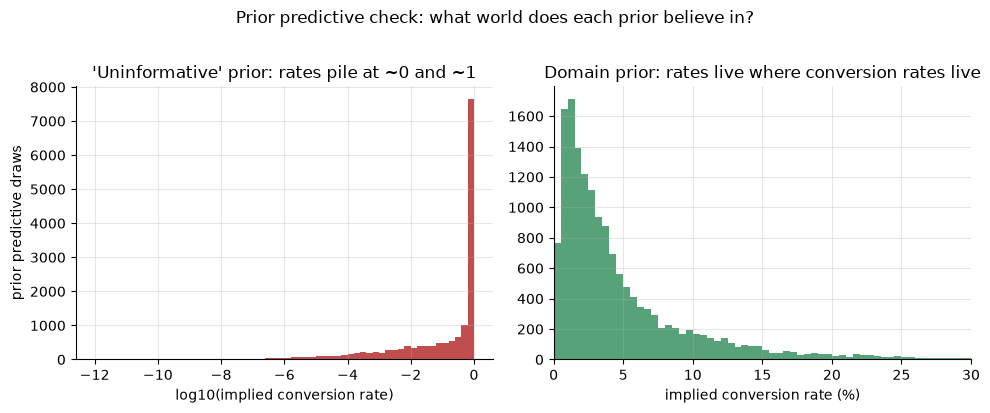

In [4]:
with hier_model(clicks, conv):                       # defaults: N(-3.5,1), HalfNormal(0.5)
    pp_good = pm.sample_prior_predictive(draws=2000, random_seed=7)
p_good = prior_rate_stats(pp_good, "domain prior  mu~N(-3.5,1), sigma~HalfNormal(0.5):")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.0))
axes[0].hist(np.log10(np.clip(p_bad, 1e-12, 1)), bins=60, color="firebrick", alpha=0.8)
axes[0].set_xlabel("log10(implied conversion rate)")
axes[0].set_ylabel("prior predictive draws")
axes[0].set_title("'Uninformative' prior: rates pile at ~0 and ~1")
axes[1].hist(p_good * 100, bins=np.linspace(0, 30, 61), color="seagreen", alpha=0.8)
axes[1].set_xlim(0, 30)
axes[1].set_xlabel("implied conversion rate (%)")
axes[1].set_title("Domain prior: rates live where conversion rates live")
fig.suptitle("Prior predictive check: what world does each prior believe in?", y=1.02)
plt.show()

The check took four lines and would have caught the absurdity before any data was
touched. That is the entire discipline: **priors are auditioned on the observable scale,
not the parameter scale.** (The wide prior is not merely ugly — Section 9 shows priors
like it actively distorting small-channel posteriors.)

## 3. Step 2 — Sampling with NUTS

What a senior candidate should be able to say about the engine, in three sentences:
Hamiltonian Monte Carlo treats $-\log p(\theta \mid y)$ as a potential-energy surface,
gives the parameter vector a random momentum, and simulates frictionless motion with a
discrete **leapfrog integrator** using gradients (PyTensor autodiff supplies them) — so
proposals travel far yet are accepted often. **NUTS** adapts the trajectory length per
iteration (stopping when the path starts doubling back), while the tuning phase adapts
the step size (targeting an acceptance rate, `target_accept`, default 0.8) and a
diagonal mass matrix. Tuning draws are discarded; they are adaptation, not posterior.

Lab-scale settings, used throughout: **2 chains × (1,000 tune + 1,000 draws), one core**
— enough for teaching-grade inference here. Production default is 4 chains (better
R-hat resolution), run in parallel.

We fit the model exactly as specified above — every parameter in its natural, *centered*
form, the way virtually everyone writes their first hierarchical model:

In [5]:
model_full_c = hier_model(clicks, conv, centered=True)
with model_full_c:
    idata_full_c = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                             random_seed=42, progressbar=False)
sampler_report(idata_full_c, "full data, centered")

rate_summary = az.summary(idata_full_c, var_names=["p"], hdi_prob=0.94)
rate_summary.index = channels
print()
print(pd.concat([data[["clicks", "obs rate", "true rate"]],
                 rate_summary[["mean", "sd", "hdi_3%", "hdi_97%"]]], axis=1))

[full data, centered]  divergences: 3  |  min bulk-ESS: 782  |  max R-hat: 1.000  |  min E-BFMI: 0.91  |  sampling: 1.7s

             clicks  obs rate  true rate   mean     sd  hdi_3%  hdi_97%
paid_search   32000    0.0244     0.0253  0.025  0.001   0.023    0.026
display       18000    0.0217     0.0208  0.022  0.001   0.020    0.024
social         9000    0.0278     0.0308  0.028  0.002   0.024    0.031
email          4000    0.0377     0.0392  0.036  0.003   0.031    0.042
affiliate      1500    0.0273     0.0279  0.028  0.004   0.020    0.034
influencer      400    0.0375     0.0356  0.032  0.006   0.022    0.044
podcast         150    0.0333     0.0230  0.030  0.007   0.018    0.043
referral         60    0.0333     0.0452  0.030  0.008   0.015    0.045


The posterior means already show partial pooling at work: podcast's raw 3.33% is pulled
down toward the portfolio mean, referral's 3.33%-on-60-clicks likewise, while
paid_search barely moves — shrinkage proportional to noise. But we are not allowed to
read this table yet, because the report line above shows **divergences: 3**.

## 4. Step 3 — Convergence diagnostics: R-hat, ESS, divergences

The checklist, and what each item certifies:

- **R-hat** (rank-normalized, split): do chains agree with each other *and* with their
  own halves? Gate: ≲ 1.01. It detects non-mixing; it cannot detect regions **no** chain
  visits.
- **ESS, bulk and tail**: how many independent draws your autocorrelated draws are
  worth — bulk for point estimates, tail for interval endpoints (tail-ESS is the one
  that dies first when geometry is bad). Rule of thumb: > ~100 per chain before you
  trust intervals.
- **Divergences**: the leapfrog integrator's discretization error exploded mid-
  trajectory — the step size tuned for the posterior's typical curvature met a region
  of much higher curvature it cannot integrate. Divergences are not noise, they are
  **evidence of a region the sampler tried and failed to enter**: estimates near that
  region are biased. A handful is a warning; hundreds are a verdict.
- **E-BFMI** (energy fraction of missing information): can momentum resampling move the
  sampler between energy levels? ≲ 0.3 flags heavy-tailed/funnel geometry.
- **Trace plots**: the eyeball check — fuzzy caterpillars that overlap, no drifts, no
  stickiness.

Our fit passes everything *except* the 3 divergences:

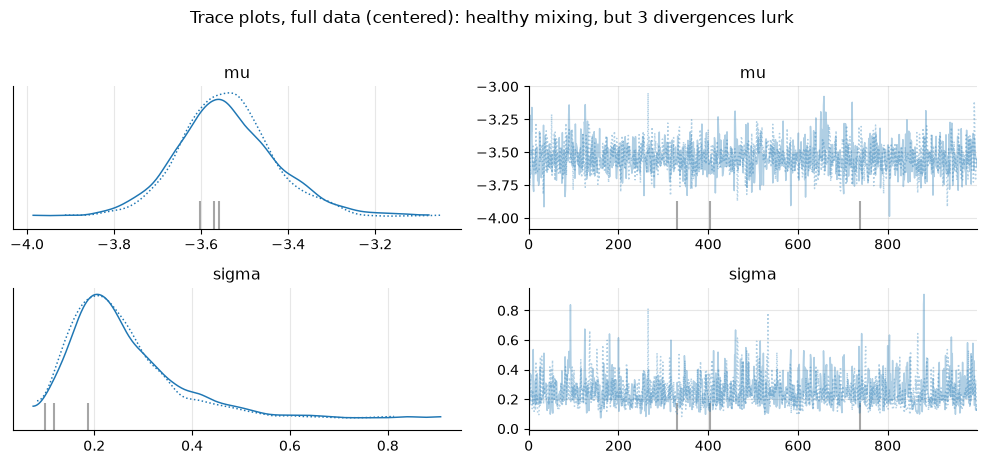

        mean     sd  ess_bulk  ess_tail  r_hat
mu    -3.541  0.112    1418.0    1115.0    1.0
sigma  0.251  0.101     782.0     674.0    1.0

E-BFMI per chain: [0.96 0.91]   divergences: 3 / 2000 draws


In [6]:
axes = az.plot_trace(idata_full_c, var_names=["mu", "sigma"], figsize=(10, 4.5))
axes.ravel()[0].figure.suptitle(
    "Trace plots, full data (centered): healthy mixing, but 3 divergences lurk", y=1.02)
plt.show()

s_full = az.summary(idata_full_c, var_names=["mu", "sigma"])
print(s_full[["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])
print(f"\nE-BFMI per chain: {np.round(az.bfmi(idata_full_c), 2)}"
      f"   divergences: {int(idata_full_c.sample_stats.diverging.sum())} / 2000 draws")

Three divergences in 2,000 draws with clean R-hat/ESS is the *mild* form of a disease
worth seeing in its acute form — because interviews ask about the acute form, and
because the mild form quietly biases $\sigma$'s lower tail. The disease lives in the
hierarchy's geometry.

## 5. The funnel: a deliberately pathological fit, and the non-centered fix

In a centered hierarchy, $\theta_c \sim \mathcal{N}(\mu, \sigma)$ makes the *scale* of
the $\theta$'s a parameter. When the likelihood is too weak to pin the $\theta_c$ down,
the joint posterior of $(\theta, \sigma)$ becomes **Neal's funnel**: at large $\sigma$
the offsets roam a wide, flat bowl; as $\sigma \to 0$ they are crushed into an
ever-narrower neck whose curvature grows without bound. One step size cannot serve both
regions — tuned for the bowl, it overshoots catastrophically in the neck (divergences);
tuned for the neck, it would random-walk the bowl.

Our full dataset only brushes this (its small channels are weakly informed, hence the 3
divergences). The launch-week pilot — 20 clicks per channel, 7 conversions total — is
the acute case. Same model, weak data:

In [7]:
model_pilot_c = hier_model(np.full(8, N_PILOT), conv_pilot, centered=True)
with model_pilot_c:
    idata_pilot_c = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                              random_seed=42, progressbar=False)
sampler_report(idata_pilot_c, "pilot data, centered")
print()
print(az.summary(idata_pilot_c, var_names=["mu", "sigma"])[
    ["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])

[pilot data, centered]  divergences: 240  |  min bulk-ESS: 25  |  max R-hat: 1.090  |  min E-BFMI: 0.30  |  sampling: 2.3s

        mean     sd  ess_bulk  ess_tail  r_hat
mu    -3.310  0.395     176.0     485.0   1.01
sigma  0.436  0.295      25.0      61.0   1.09


Catastrophe, fully flagged: **~12% of all post-tuning draws are divergent**, $\sigma$'s
R-hat fails the 1.01 gate, its bulk ESS collapses to a few dozen, and E-BFMI sits near
0.3. This posterior is not usable — and the workflow's diagnostics said so loudly.

**The fix is a change of coordinates, not more compute.** Write each offset as a scaled
standard normal — the **non-centered parameterization**:

$$z_c \sim \mathcal{N}(0, 1), \qquad \theta_c = \mu + \sigma \, z_c .$$

Identical joint distribution, but the sampler now works in $(z, \mu, \sigma)$ space,
where the prior geometry is a fixed isotropic Gaussian — the funnel's
$\sigma$-dependent curvature has been transformed away; $\sigma$ re-enters only through
the (weak) likelihood. `hier_model(..., centered=False)` already implements it:

In [8]:
model_pilot_nc = hier_model(np.full(8, N_PILOT), conv_pilot, centered=False)
with model_pilot_nc:
    idata_pilot_nc = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                               random_seed=42, progressbar=False)
sampler_report(idata_pilot_nc, "pilot data, non-centered")
print()
print(az.summary(idata_pilot_nc, var_names=["mu", "sigma"])[
    ["mean", "sd", "ess_bulk", "ess_tail", "r_hat"]])

[pilot data, non-centered]  divergences: 0  |  min bulk-ESS: 767  |  max R-hat: 1.000  |  min E-BFMI: 0.95  |  sampling: 1.9s

        mean     sd  ess_bulk  ess_tail  r_hat
mu    -3.291  0.434    1130.0     779.0    1.0
sigma  0.430  0.305     767.0     875.0    1.0


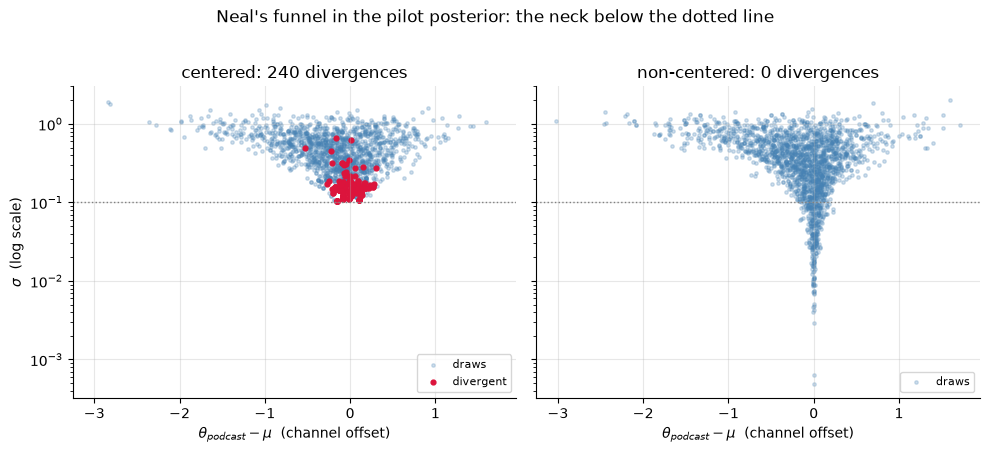

posterior mass on sigma < 0.1:  centered 0.0%   non-centered 13.4%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, sharex=True)
for ax, idata, name in [(axes[0], idata_pilot_c, "centered"),
                        (axes[1], idata_pilot_nc, "non-centered")]:
    off = (idata.posterior["theta"].sel(channel="podcast")
           - idata.posterior["mu"]).values.ravel()
    sig = idata.posterior["sigma"].values.ravel()
    div = idata.sample_stats["diverging"].values.ravel()
    ax.scatter(off[~div], sig[~div], s=6, alpha=0.25, color="steelblue", label="draws")
    if div.any():
        ax.scatter(off[div], sig[div], s=12, color="crimson", label="divergent")
    ax.axhline(0.1, color="gray", ls=":", lw=1)
    ax.set_yscale("log")
    ax.set_xlabel(r"$\theta_{podcast} - \mu$  (channel offset)")
    n_div = int(div.sum())
    ax.set_title(f"{name}: {n_div} divergences")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel(r"$\sigma$  (log scale)")
fig.suptitle("Neal's funnel in the pilot posterior: the neck below the dotted line", y=1.02)
plt.show()

neck = {"centered": float((idata_pilot_c.posterior["sigma"] < 0.1).mean()),
        "non-centered": float((idata_pilot_nc.posterior["sigma"] < 0.1).mean())}
print(f"posterior mass on sigma < 0.1:  centered {neck['centered']:.1%}   "
      f"non-centered {neck['non-centered']:.1%}")

The picture is the answer to the interview question. The centered sampler's cloud stops
dead above the neck — it places **zero** posterior mass on $\sigma < 0.1$, a region
where the non-centered sampler (correctly) puts ~13%. The divergences cluster exactly at
the boundary it could not cross: they are the sampler drawing you a map of its own
failure. Note the means barely differ — the bias hides in the tail that determines
"could the channels actually all be the same?", precisely the question a hierarchical
model exists to answer.

**The senior twist: non-centering is not a universal upgrade.** With *strong* per-group
data the likelihood pins each $\theta_c$; in non-centered coordinates the sampler must
then thread $z_c = (\theta_c - \mu)/\sigma$ through a $\sigma$-dependent constraint —
reintroducing exactly the kind of coupling it removed. Fit both parameterizations on
both datasets and the pattern is clean:

In [10]:
model_full_nc = hier_model(clicks, conv, centered=False)
with model_full_nc:
    idata_full_nc = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                              random_seed=42, progressbar=False)
sampler_report(idata_full_nc, "full data, non-centered")
print()
print(pd.DataFrame(fit_log).set_index("fit").round(3))

[full data, non-centered]  divergences: 6  |  min bulk-ESS: 486  |  max R-hat: 1.000  |  min E-BFMI: 0.84  |  sampling: 4.3s

                          divergences  min bulk-ESS  min tail-ESS  max R-hat  min E-BFMI  sampling s
fit                                                                                                 
full data, centered                 3           782           674       1.00       0.907       1.742
pilot data, centered              240            25            61       1.09       0.305       2.271
pilot data, non-centered            0           767           779       1.00       0.947       1.928
full data, non-centered             6           486           389       1.00       0.840       4.264


Weak data (pilot): centered is broken, non-centered is flawless. Strong-but-mixed data
(full): *neither* is flawless — the data-rich channels favor centered, the data-poor
tail favors non-centered, and both leave a few divergences. The rule of thumb:
**non-center the weakly-identified groups, center the strongly-identified ones** (mixed
parameterizations per group are legitimate and occasionally necessary).

For the full data we take the cheaper route that the diagnostics justify: keep the
centered form and raise `target_accept` to 0.9 — a smaller step size, appropriate here
because the pathology is mild. **After any such change you re-verify**; band-aiding a
*severe* funnel this way is Pitfall 1.

In [11]:
with model_full_c:
    idata_full = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                           target_accept=0.9, random_seed=42, progressbar=False)
final_row = sampler_report(idata_full, "full data, centered, target_accept=0.9")

[full data, centered, target_accept=0.9]  divergences: 0  |  min bulk-ESS: 878  |  max R-hat: 1.000  |  min E-BFMI: 0.78  |  sampling: 2.1s


Zero divergences, healthy ESS and E-BFMI: *this* is the fit the rest of the notebook is
allowed to use.

## 6. Step 4 — Posterior predictive checks

Diagnostics certify the *sampling*; they say nothing about whether the *model* fits.
The posterior predictive check asks: if this fitted model were true, would data like
ours be unsurprising? We simulate replicated datasets $y^{rep}$ from the posterior and
compare them to the observed conversions, channel by channel.

To show a PPC actually *failing*, we also fit the natural straw man — **complete
pooling**, one shared rate for all channels (conjugate Beta posterior, closed form as
in [01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb), so it costs
nothing):

hierarchical model: observed rate outside the 94% predictive interval for no channel
complete pooling: observed rate outside the 94% predictive interval for ['display', 'email']


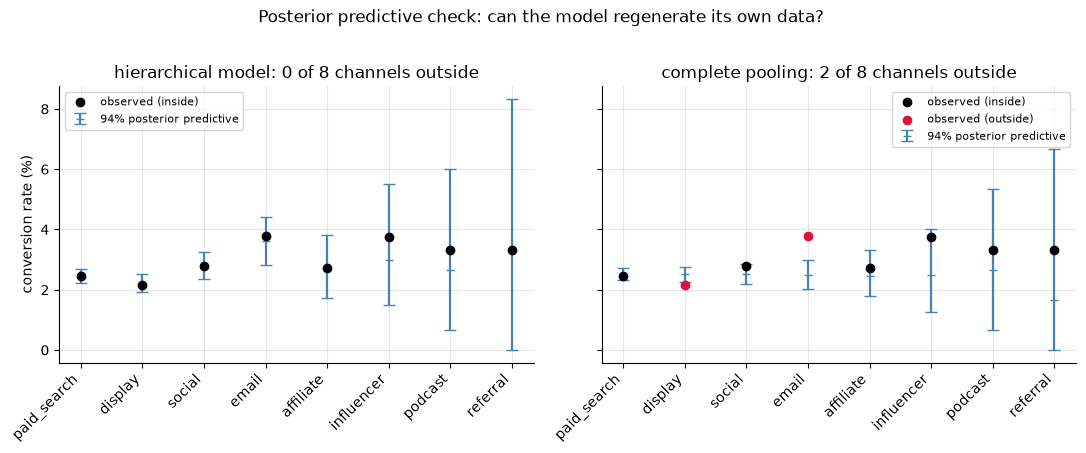

In [12]:
with model_full_c:
    ppc = pm.sample_posterior_predictive(idata_full, random_seed=42, progressbar=False)
rate_rep = ppc.posterior_predictive["y"].values.reshape(-1, 8) / clicks

# complete pooling: p ~ Beta(1 + total conv, 1 + total misses), then per-channel binomial
p_pool = rng.beta(1 + conv.sum(), 1 + (clicks - conv).sum(), size=2000)
rate_pool = rng.binomial(clicks[None, :], p_pool[:, None]) / clicks

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
x = np.arange(8)
obs_rate = conv / clicks
for ax, rep, name in [(axes[0], rate_rep, "hierarchical model"),
                      (axes[1], rate_pool, "complete pooling")]:
    lo, mid, hi = np.percentile(rep, [3, 50, 97], axis=0)
    outside = (obs_rate < lo) | (obs_rate > hi)
    ax.errorbar(x, mid * 100, yerr=[(mid - lo) * 100, (hi - mid) * 100],
                fmt="_", color="steelblue", capsize=4, lw=1.6,
                label="94% posterior predictive")
    ax.scatter(x[~outside], obs_rate[~outside] * 100, color="black", zorder=3,
               label="observed (inside)")
    if outside.any():
        ax.scatter(x[outside], obs_rate[outside] * 100, color="crimson", zorder=3,
                   label="observed (outside)")
    ax.set_xticks(x, channels, rotation=45, ha="right")
    ax.set_title(f"{name}: {int(outside.sum())} of 8 channels outside")
    ax.legend(fontsize=8)
    misses = [c for c, o in zip(channels, outside) if o]
    print(f"{name}: observed rate outside the 94% predictive interval for "
          f"{misses if misses else 'no channel'}")
axes[0].set_ylabel("conversion rate (%)")
fig.suptitle("Posterior predictive check: can the model regenerate its own data?", y=1.02)
plt.show()

The hierarchical model regenerates every channel comfortably. Complete pooling is
rejected by exactly the channels with enough volume to expose it — email converts far
above anything a single shared rate produces, display below — while the tiny channels'
huge sampling noise lets it "pass" there. Two habits worth naming:

- **PPC power lives in the test statistic.** Per-channel rates catch this failure;
  aggregate statistics may not (Exercise 3 quantifies this with a Bayesian p-value).
- **A PPC is a sanity check, not validation.** The data was used twice, so passing is
  necessary, never sufficient — an overfit (saturated) model passes trivially. For
  genuine model *comparison* use held-out log score or PSIS-LOO (`az.loo`/`az.compare`);
  honest out-of-sample discipline is the same religion as
  [../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb).

## 7. Step 5 — The decision: where does the next \$50k go?

The business quantity is not $\theta_c$; it is **conversions bought per \$50k** in each
*buyable* channel (email and referral are organic — no CPC, not scalable):

$$Q_c = \frac{\$50{,}000}{\mathrm{CPC}_c} \times p_c ,$$

assuming, explicitly, constant marginal CPC and conversion (no saturation — the
assumption to state out loud in any real readout). First, what the point-estimate
spreadsheet every marketing team builds would say — observed rates, no uncertainty:

In [13]:
BUDGET = 50_000
buyable = ~np.isnan(cpc)
buy_names = [c for c, b in zip(channels, buyable) if b]

naive_q = BUDGET / cpc[buyable] * obs_rate[buyable]
true_q = BUDGET / cpc[buyable] * true_p[buyable]

naive = pd.DataFrame({"CPC ($)": cpc[buyable], "obs rate": obs_rate[buyable],
                      "conv per $50k (MLE)": naive_q.round(0)}, index=buy_names)
print(naive.sort_values("conv per $50k (MLE)", ascending=False))
print(f"\nspreadsheet says: scale {buy_names[int(np.argmax(naive_q))].upper()}")

             CPC ($)  obs rate  conv per $50k (MLE)
podcast         0.45    0.0333               3704.0
display         0.30    0.0217               3611.0
affiliate       0.40    0.0273               3417.0
social          0.50    0.0278               2778.0
influencer      0.90    0.0375               2083.0
paid_search     0.85    0.0244               1436.0

spreadsheet says: scale PODCAST


The spreadsheet picks **podcast** — a channel whose entire case is 5 conversions on 150
clicks at a low CPC. This is the winner's curse in miniature: rank noisy point
estimates and the noisiest lucky channel floats to the top (the selection variant of
regression to the mean —
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb)).

The Bayesian readout pushes the *joint posterior* through the same formula. Shrinkage
de-biases the lucky small channels, and the draws give the quantities a decision
actually needs: P(best), intervals, and the expected cost of being wrong:

In [14]:
p_draws = idata_full.posterior["p"].values.reshape(-1, 8)      # (2000, 8)
q_draws = BUDGET / cpc[buyable] * p_draws[:, buyable]          # (2000, 6)

best = np.argmax(q_draws, axis=1)
p_best = np.bincount(best, minlength=len(buy_names)) / len(best)
regret = (q_draws.max(axis=1, keepdims=True) - q_draws).mean(axis=0)

decision = pd.DataFrame({
    "MLE": naive_q.round(0),
    "post mean": q_draws.mean(axis=0).round(0),
    "post 5%": np.percentile(q_draws, 5, axis=0).round(0),
    "post 95%": np.percentile(q_draws, 95, axis=0).round(0),
    "P(best)": p_best,
    "E[regret] (conv)": regret.round(0),
    "truth": true_q.round(0),
}, index=buy_names).sort_values("post mean", ascending=False)
print(decision)

pick = decision.index[0]
print(f"\nrecommendation: {pick.upper()} — highest expected conversions, "
      f"minimum expected regret ({decision.loc[pick, 'E[regret] (conv)']:.0f} conversions)")
print(f"truth receipt: the naive podcast pick would truly deliver "
      f"{true_q[buy_names.index('podcast')]:.0f} conversions vs "
      f"{true_q[buy_names.index(pick)]:.0f} for {pick} "
      f"(true best: {buy_names[int(np.argmax(true_q))]}, {true_q.max():.0f})")

                MLE  post mean  post 5%  post 95%  P(best)  E[regret] (conv)   truth
display      3611.0     3663.0   3361.0    3959.0   0.5205             245.0  3473.0
affiliate    3417.0     3447.0   2759.0    4155.0   0.2390             460.0  3490.0
podcast      3704.0     3296.0   2223.0    4760.0   0.2400             611.0  2553.0
social       2778.0     2783.0   2525.0    3060.0   0.0005            1124.0  3077.0
influencer   2083.0     1773.0   1297.0    2386.0   0.0000            2134.0  1976.0
paid_search  1436.0     1441.0   1363.0    1525.0   0.0000            2466.0  1490.0

recommendation: DISPLAY — highest expected conversions, minimum expected regret (245 conversions)
truth receipt: the naive podcast pick would truly deliver 2553 conversions vs 3473 for display (true best: affiliate, 3490)


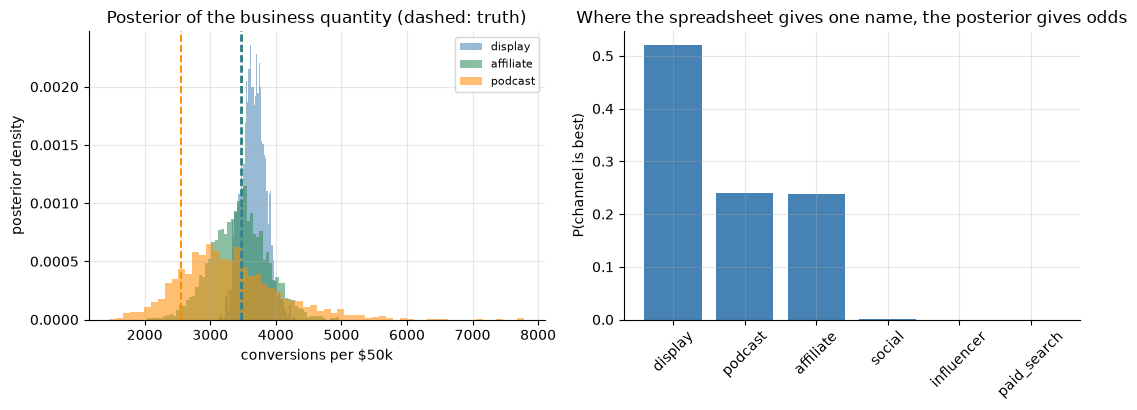

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, color in [("display", "steelblue"), ("affiliate", "seagreen"),
                    ("podcast", "darkorange")]:
    j = buy_names.index(name)
    axes[0].hist(q_draws[:, j], bins=60, density=True, alpha=0.55, color=color,
                 label=name)
    axes[0].axvline(true_q[j], color=color, ls="--", lw=1.4)
axes[0].set_xlabel("conversions per $50k")
axes[0].set_ylabel("posterior density")
axes[0].set_title("Posterior of the business quantity (dashed: truth)")
axes[0].legend(fontsize=8)

order = np.argsort(p_best)[::-1]
axes[1].bar([buy_names[i] for i in order], p_best[order], color="steelblue")
axes[1].set_ylabel("P(channel is best)")
axes[1].set_title("Where the spreadsheet gives one name, the posterior gives odds")
axes[1].tick_params(axis="x", rotation=45)
plt.show()

The senior readout, in stakeholder language: **display is the pick** — best expected
return and the least to lose — but it is roughly a coin-flip-plus, not a certainty:
affiliate is a genuine contender (the truth receipt shows they are, in fact, nearly
tied), and podcast's spreadsheet crown was luck, worth ~900 fewer true conversions than
display per \$50k. The posterior also prices the *value of information*: podcast and
affiliate's intervals are wide because their data is thin — a small test budget there
buys real learning. Optimizing that explore/exploit trade continuously is Thompson
sampling — [04_bandits_thompson.ipynb](./04_bandits_thompson.ipynb).

## 8. Side-by-side with the frequentist GLM

The frequentist workhorse for this data is a binomial GLM with a dummy per channel (no
pooling) — [../01_statistical_foundations/03_regression_the_workhorse.ipynb](../01_statistical_foundations/03_regression_the_workhorse.ipynb)'s
machinery. To make the comparison exact we fit the *same* no-pooling model in PyMC
under (near-)flat priors — accepting, for comparability, the very prior Section 2
rejected. MLE ↔ posterior mode under a flat prior, so the numbers should agree:

In [16]:
X = np.eye(8)
with warnings.catch_warnings():
    # the no-pooling design is saturated (8 observations, 8 parameters): statsmodels
    # warns about df_resid = 0 and "perfect prediction"; both are structural and harmless
    warnings.simplefilter("ignore")
    glm = sm.GLM(np.column_stack([conv, clicks - conv]), X,
                 family=sm.families.Binomial()).fit()


def nopool_model(n, y, prior_mu=0.0, prior_sd=10.0):
    with pm.Model(coords={"channel": channels}) as m:
        theta = pm.Normal("theta", prior_mu, prior_sd, dims="channel")
        pm.Deterministic("p", pm.math.invlogit(theta), dims="channel")
        pm.Binomial("y", n=n, p=pm.math.invlogit(theta), observed=y, dims="channel")
    return m


model_flat = nopool_model(clicks, conv)
with model_flat:
    idata_flat = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                           random_seed=42, progressbar=False)
sampler_report(idata_flat, "full data, no pooling, flat priors", store=False)

th = idata_flat.posterior["theta"].values.reshape(-1, 8)
side = pd.DataFrame({
    "clicks": clicks,
    "GLM MLE (logit)": glm.params, "GLM SE": glm.bse,
    "Bayes mean (logit)": th.mean(axis=0), "Bayes sd": th.std(axis=0),
}, index=channels)
print()
print(side)
gap = np.abs(glm.params - th.mean(axis=0))
print(f"\n|MLE - posterior mean| on the logit scale: four largest channels within "
      f"{gap[:4].max():.4f}; worst overall {gap.max():.3f} (referral, n=60)")

[full data, no pooling, flat priors]  divergences: 0  |  min bulk-ESS: 2065  |  max R-hat: 1.010  |  min E-BFMI: 1.13  |  sampling: 1.1s

             clicks  GLM MLE (logit)  GLM SE  Bayes mean (logit)  Bayes sd
paid_search   32000          -3.6882  0.0362             -3.6871    0.0351
display       18000          -3.8101  0.0512             -3.8108    0.0492
social         9000          -3.5553  0.0641             -3.5577    0.0665
email          4000          -3.2383  0.0830             -3.2388    0.0848
affiliate      1500          -3.5719  0.1584             -3.5838    0.1595
influencer      400          -3.2452  0.2632             -3.2720    0.2723
podcast         150          -3.3673  0.4549             -3.4509    0.4524
referral         60          -3.3673  0.7192             -3.6044    0.8026

|MLE - posterior mean| on the logit scale: four largest channels within 0.0023; worst overall 0.237 (referral, n=60)


As advertised: with flat priors and non-trivial counts, Bayes-via-MCMC reproduces the
GLM — same likelihood, same optimum, and the posterior sd tracks the Wald SE. (The
small channels drift a little: their likelihoods are skewed, so posterior *mean* ≠
mode, and the "flat" prior's tails start to matter — a preview of Section 9.) If point
estimates of $\theta$ were the deliverable, PyMC would be an expensive way to run
`statsmodels`.

**The payoff is downstream, on derived quantities.** Take podcast's cost per
acquisition, $\mathrm{CPA} = \mathrm{CPC}/p$ — a nonlinear transform of an uncertain
quantity estimated from 5 events. The frequentist route is the delta method
([../02_ab_testing/05_ratio_metrics_delta_method.ipynb](../02_ab_testing/05_ratio_metrics_delta_method.ipynb)):
a symmetric normal CI. The Bayesian route is one line: transform the draws.

podcast CPA, GLM + delta method: $13.50 +/- 11.63 -> 95% CI [$1.87, $25.13]
podcast CPA, posterior (flat prior): median $14.37, 95% interval [$6.80, $37.79]
P(CPA > $20):  posterior 23.1%   delta-normal 13.7%
P(CPA < $5):   posterior 0.1%    delta-normal 7.6%


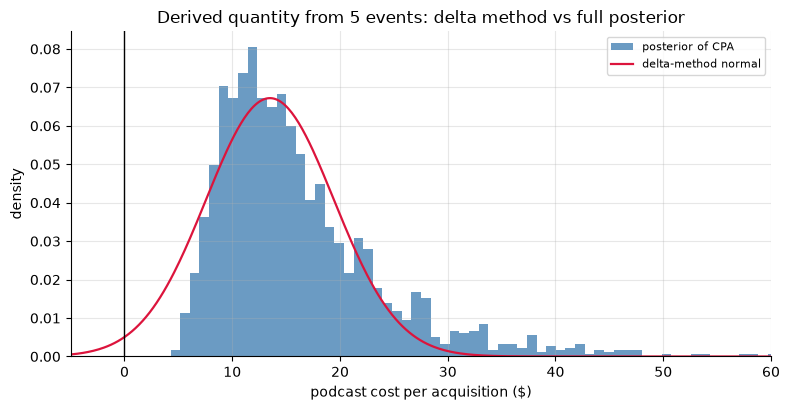

In [17]:
i_pod = channels.index("podcast")
p_hat = obs_rate[i_pod]
se_p = p_hat * (1 - p_hat) * glm.bse[i_pod]          # delta method, logit -> p
cpa_hat = cpc[i_pod] / p_hat
se_cpa = cpc[i_pod] / p_hat**2 * se_p                # delta method, p -> CPA
ci_delta = (cpa_hat - 1.96 * se_cpa, cpa_hat + 1.96 * se_cpa)

cpa_draws = cpc[i_pod] / invlogit(th[:, i_pod])
q_cpa = np.percentile(cpa_draws, [2.5, 50, 97.5])

print(f"podcast CPA, GLM + delta method: ${cpa_hat:.2f} +/- {1.96 * se_cpa:.2f} "
      f"-> 95% CI [${ci_delta[0]:.2f}, ${ci_delta[1]:.2f}]")
print(f"podcast CPA, posterior (flat prior): median ${q_cpa[1]:.2f}, "
      f"95% interval [${q_cpa[0]:.2f}, ${q_cpa[2]:.2f}]")
print(f"P(CPA > $20):  posterior {(cpa_draws > 20).mean():.1%}   "
      f"delta-normal {stats.norm.sf((20 - cpa_hat) / se_cpa):.1%}")
print(f"P(CPA < $5):   posterior {(cpa_draws < 5).mean():.1%}    "
      f"delta-normal {stats.norm.cdf((5 - cpa_hat) / se_cpa):.1%}")

fig, ax = plt.subplots()
ax.hist(cpa_draws, bins=80, density=True, color="steelblue", alpha=0.8,
        label="posterior of CPA")
grid = np.linspace(-5, 60, 400)
ax.plot(grid, stats.norm.pdf(grid, cpa_hat, se_cpa), color="crimson", lw=1.6,
        label="delta-method normal")
ax.axvline(0, color="black", lw=1)
ax.set_xlim(-5, 60)
ax.set_xlabel("podcast cost per acquisition ($)")
ax.set_ylabel("density")
ax.set_title("Derived quantity from 5 events: delta method vs full posterior")
ax.legend(fontsize=8)
plt.show()

The delta-method interval is symmetric by construction, so it misallocates both tails:
it puts ~8% probability on CPA below \$5 — economically absurd, since that would need a
~9% conversion rate from a channel that showed 3.3% on 150 clicks (the posterior says
0.1%) — while carrying only ~14% above \$20, where the posterior holds 23%. And \$20 is
the tail that matters: it is roughly where podcast stops competing with display. Same
data, same "flat" assumptions; the posterior is simply the correct shape of the
uncertainty, and it composes: the Section 7 decision table (P(best), expected regret)
falls out of the draws with no new theory. *That* — full distributions on arbitrary
derived quantities — is what you are buying with the sampler, not different point
estimates.

## 9. Small data: the launch week, where priors earn their keep

Rewind to week one: 20 clicks per channel, 7 conversions total. The frequentist
toolkit is structurally broken here, not just noisy:

In [18]:
mle = conv_pilot / N_PILOT
wald_se = np.sqrt(mle * (1 - mle) / N_PILOT)
pilot_tbl = pd.DataFrame({
    "conversions (of 20)": conv_pilot, "MLE rate": mle,
    "Wald 95% lo": mle - 1.96 * wald_se, "Wald 95% hi": mle + 1.96 * wald_se,
    "true rate": true_p,
}, index=channels)
print(pilot_tbl)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    glm_pilot = sm.GLM(np.column_stack([conv_pilot, N_PILOT - conv_pilot]), X,
                       family=sm.families.Binomial()).fit()
print(f"\nstatsmodels warnings raised: {sorted({w.category.__name__ for w in caught})}")
print(f"GLM logit estimate for social (0/20):  {glm_pilot.params[2]:.1f}  "
      f"(SE {glm_pilot.bse[2]:,.0f}) — i.e. p = 0 with an unidentified parameter")

             conversions (of 20)  MLE rate  Wald 95% lo  Wald 95% hi  true rate
paid_search                    0      0.00       0.0000       0.0000     0.0253
display                        0      0.00       0.0000       0.0000     0.0208
social                         0      0.00       0.0000       0.0000     0.0308
email                          2      0.10      -0.0315       0.2315     0.0392
affiliate                      1      0.05      -0.0455       0.1455     0.0279
influencer                     1      0.05      -0.0455       0.1455     0.0356
podcast                        0      0.00       0.0000       0.0000     0.0230
referral                       3      0.15      -0.0065       0.3065     0.0452

statsmodels warnings raised: ['PerfectSeparationWarning', 'RuntimeWarning']
GLM logit estimate for social (0/20):  -24.6  (SE 29,295) — i.e. p = 0 with an unidentified parameter


Four channels report a 0% conversion rate with the Wald interval **[0%, 0%]** — total
certainty in an impossible value — and the GLM declares *perfect separation*: the MLE
for those channels is $-\infty$ on the logit scale (statsmodels stops around $-24$ with
an SE in the tens of thousands). Meanwhile referral's 3/20 reports 15%, triple its
truth. The MLE is not wrong — it is the honest maximum of a likelihood that 20 clicks
cannot make informative. The information has to come from somewhere else.

A defensible **informative prior** is that somewhere: industry benchmarks put
click-to-paid conversion at roughly 1–10%, encoded as $\theta_c \sim
\mathcal{N}(\mathrm{logit}(0.03),\, 0.7)$ — 95% of prior mass between 0.8% and 11%.
(Same no-pooling structure as the GLM; only the prior changes.)

In [19]:
model_inf = nopool_model(np.full(8, N_PILOT), conv_pilot,
                         prior_mu=float(logit(0.03)), prior_sd=0.7)
with model_inf:
    idata_inf = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                          random_seed=42, progressbar=False)
sampler_report(idata_inf, "pilot, no pooling, informative prior", store=False)

p_inf = idata_inf.posterior["p"].values.reshape(-1, 8)
inf_tbl = pd.DataFrame({
    "MLE rate": mle, "posterior mean": p_inf.mean(axis=0),
    "post 3%": np.percentile(p_inf, 3, axis=0),
    "post 97%": np.percentile(p_inf, 97, axis=0),
    "true rate": true_p,
}, index=channels)
print(inf_tbl)

rmse_mle = np.sqrt(np.mean((mle - true_p) ** 2))
rmse_bayes = np.sqrt(np.mean((p_inf.mean(axis=0) - true_p) ** 2))
print(f"\nRMSE vs truth across channels:  MLE {rmse_mle * 100:.2f}pp   "
      f"informative-prior posterior mean {rmse_bayes * 100:.2f}pp   "
      f"({rmse_mle / rmse_bayes:.1f}x better)")

[pilot, no pooling, informative prior]  divergences: 0  |  min bulk-ESS: 1846  |  max R-hat: 1.000  |  min E-BFMI: 1.10  |  sampling: 0.9s
             MLE rate  posterior mean  post 3%  post 97%  true rate
paid_search      0.00          0.0265   0.0069    0.0699     0.0253
display          0.00          0.0277   0.0071    0.0705     0.0208
social           0.00          0.0268   0.0067    0.0657     0.0308
email            0.10          0.0522   0.0157    0.1211     0.0392
affiliate        0.05          0.0390   0.0110    0.0921     0.0279
influencer       0.05          0.0385   0.0104    0.0947     0.0356
podcast          0.00          0.0276   0.0073    0.0703     0.0230
referral         0.15          0.0705   0.0218    0.1530     0.0452

RMSE vs truth across channels:  MLE 4.73pp   informative-prior posterior mean 1.13pp   (4.2x better)


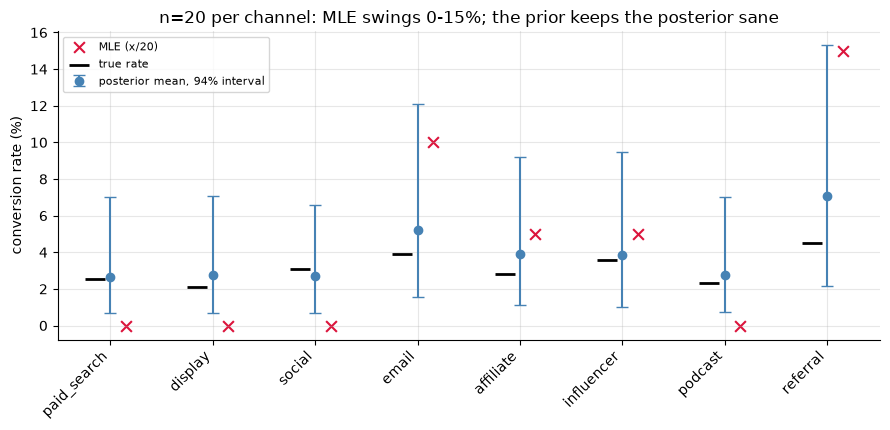

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.4))
xj = np.arange(8)
ax.errorbar(xj, p_inf.mean(axis=0) * 100,
            yerr=[(p_inf.mean(axis=0) - np.percentile(p_inf, 3, axis=0)) * 100,
                  (np.percentile(p_inf, 97, axis=0) - p_inf.mean(axis=0)) * 100],
            fmt="o", color="steelblue", capsize=4, label="posterior mean, 94% interval")
ax.scatter(xj + 0.15, mle * 100, marker="x", s=60, color="crimson", label="MLE (x/20)")
ax.scatter(xj - 0.15, true_p * 100, marker="_", s=200, color="black", lw=2,
           label="true rate")
ax.set_xticks(xj, channels, rotation=45, ha="right")
ax.set_ylabel("conversion rate (%)")
ax.set_title(f"n=20 per channel: MLE swings 0-15%; the prior keeps the posterior sane")
ax.legend(fontsize=8)
plt.show()

The prior acts as principled regularization: zero-conversion channels land near 2.7%
(not 0%), referral's lucky 15% is pulled to ~7%, and the error versus truth drops by a
factor of ~4. This is the regime where "Bayesian vs frequentist" stops being
philosophy: with 20 observations, *whoever brings valid outside information wins*, and
the prior is the audited, explicit way to bring it. Two provisos a senior candidate
volunteers unprompted: a *wrong* prior at this n dominates the answer just as strongly
(the coverage collapse is measured in
[01_bayesian_ab_testing.ipynb](./01_bayesian_ab_testing.ipynb), Section 9), and the
systematic version of "outside information" is learning the prior from the other
channels — the hierarchical model of
[03_hierarchical_models.ipynb](./03_hierarchical_models.ipynb).

## 10. Pitfalls

### Pitfall 1: band-aiding divergences with `target_accept`

The standard reflex to divergences is `target_accept=0.99` — force a smaller step size.
On a real funnel this is a costly gamble you cannot grade from the inside:

In [21]:
with model_pilot_c:
    idata_pilot_c99 = pm.sample(draws=1000, tune=1000, chains=2, cores=1,
                                target_accept=0.99, random_seed=42, progressbar=False)
row99 = sampler_report(idata_pilot_c99, "pilot centered, target_accept=0.99", store=False)

neck_tbl = pd.DataFrame({
    "divergences": [fit_log[1]["divergences"], row99["divergences"],
                    fit_log[2]["divergences"]],
    "sampling s": [fit_log[1]["sampling s"], row99["sampling s"],
                   fit_log[2]["sampling s"]],
    "min E-BFMI": [fit_log[1]["min E-BFMI"], row99["min E-BFMI"],
                   fit_log[2]["min E-BFMI"]],
    "P(sigma < 0.1)": [neck["centered"],
                       float((idata_pilot_c99.posterior["sigma"] < 0.1).mean()),
                       neck["non-centered"]],
    "max R-hat": [fit_log[1]["max R-hat"], row99["max R-hat"], fit_log[2]["max R-hat"]],
}, index=["centered, ta=0.8", "centered, ta=0.99", "non-centered, ta=0.8"])
print()
print(neck_tbl.round(3))
prior_neck = 2 * (stats.norm.cdf(0.1 / 0.5) - 0.5)
print(f"\nfor reference, the prior alone puts {prior_neck:.1%} of sigma's mass below 0.1 "
      f"— weak data cannot have erased it")

[pilot centered, target_accept=0.99]  divergences: 7  |  min bulk-ESS: 76  |  max R-hat: 1.010  |  min E-BFMI: 0.22  |  sampling: 14.9s

                      divergences  sampling s  min E-BFMI  P(sigma < 0.1)  max R-hat
centered, ta=0.8              240       2.271       0.305           0.000       1.09
centered, ta=0.99               7      14.934       0.220           0.130       1.01
non-centered, ta=0.8            0       1.928       0.947           0.134       1.00

for reference, the prior alone puts 15.9% of sigma's mass below 0.1 — weak data cannot have erased it


Read the table the way a reviewer would. The brute-force run cuts divergences from 240
to 7 and — *in this instance* — recovers roughly the right neck mass (0.130 vs the
non-centered 0.134). So did the band-aid work? You could not know without the
non-centered reference: the fit still cannot certify itself — divergences persist,
E-BFMI got *worse* (0.22), and $\sigma$'s ESS is ~40 per chain, all at ~6× the
sampling cost. Compare the last row: the reparameterization costs no more than the
*original* broken fit, diverges zero times, and delivers ~10× the effective draws.
Cranking `target_accept` is defensible for mild geometry (we used 0.9 in Section 5);
as a response to *structural* divergences it buys you an expensive fit you still
cannot trust. Reparameterize.

### Pitfall 2: treating R-hat ≈ 1.01 as a certificate of correctness

The `ta=0.99` row passes the classic R-hat gate (≈1.01) while 7 divergences and a
bulk-ESS of 76 say "do not ship". R-hat only detects chains *disagreeing*: chains that
all fail the same way — every chain locked out of the funnel neck, as in the centered
fit — can agree beautifully on a biased answer (here the ta=0.8 run happened to also
trip R-hat via $\sigma$'s sluggish mixing, but nothing guarantees that courtesy). The
diagnostics form a hierarchy, not a menu: R-hat and ESS are necessary; divergences and
E-BFMI catch what R-hat structurally cannot; posterior predictive checks catch what no
sampler diagnostic can (a converged fit of a wrong model, Section 6). You need all of
them, which is why the workflow runs all of them.

### Pitfall 3: reading marginal intervals instead of the joint posterior

"Display's interval overlaps affiliate's, so we can't say which is better" — the
Bayesian rerun of the overlapping-CIs fallacy
([../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb](../01_statistical_foundations/02_hypothesis_testing_beyond_basics.ipynb)).
Comparisons live in the *joint* draws, not in two marginal summaries:

In [22]:
jd, ja = buy_names.index("display"), buy_names.index("affiliate")
lo_d, hi_d = np.percentile(q_draws[:, jd], [5, 95])
lo_a, hi_a = np.percentile(q_draws[:, ja], [5, 95])
print(f"conversions per $50k, 90% intervals: display [{lo_d:.0f}, {hi_d:.0f}]  "
      f"affiliate [{lo_a:.0f}, {hi_a:.0f}]  -> heavily overlapping")
diff = q_draws[:, jd] - q_draws[:, ja]
print(f"P(display > affiliate) from the joint draws: {(diff > 0).mean():.1%}  "
      f"(posterior mean gap {diff.mean():+.0f} conversions)")
print(f"correlation between the two quantities' draws: "
      f"{np.corrcoef(q_draws[:, jd], q_draws[:, ja])[0, 1]:+.2f} "
      f"(negligible here — both channels are data-dominated; on weak data the shared "
      f"hyperparameters make it large)")

conversions per $50k, 90% intervals: display [3361, 3959]  affiliate [2759, 4155]  -> heavily overlapping
P(display > affiliate) from the joint draws: 69.0%  (posterior mean gap +215 conversions)
correlation between the two quantities' draws: +0.03 (negligible here — both channels are data-dominated; on weak data the shared hyperparameters make it large)


Overlapping 90% intervals coexist with a ~2:1 probability in display's favor. Interval
arithmetic implicitly assumes the difference's distribution can be reconstructed from
two marginals — it cannot in general: here the draws happen to be nearly independent
(both posteriors are data-dominated), but in weak-data hierarchical settings the shared
hyperparameters correlate them strongly, and no pair of marginal intervals encodes
that. Every multi-way readout — P(best), rankings, differences, regret — must be
computed **per-draw, then summarized**, never assembled from marginal summaries. (Same
discipline as Section 7's decision table.)

## 11. Interview corner

**1. "What are divergences, and what do you do when you see them?"**
A divergence is a NUTS transition whose leapfrog integration error blew up — the step
size adapted to typical posterior curvature hit a region of extreme curvature. They
matter because they mark regions the sampler *tried and failed to explore*: estimates
are biased near them, and they concentrate exactly where the geometry is pathological
(our funnel neck). Response ladder: (1) look at *where* they cluster (pair plots vs a
scale parameter); (2) if mild and unclustered, raise `target_accept` moderately and
re-verify; (3) if structural — hierarchical scales, especially with weak data —
reparameterize (non-centered), or rethink the model (tighter priors, more informative
likelihood). Never report a posterior from a heavily divergent fit; a few hundred in a
few thousand draws made our centered fit put 0% mass where 13% belonged.

**2. "How do you check a Bayesian model?"**
Before data: prior predictive simulation — do the priors generate plausible datasets on
the observable scale? After sampling, computation checks: R-hat ≲ 1.01, bulk/tail ESS
in the hundreds, zero (or explained) divergences, healthy E-BFMI, clean traces. Then
model checks: posterior predictive against observed data with test statistics chosen to
have power against the failures you fear; sensitivity analysis on the priors that
matter; held-out log score or PSIS-LOO if models are competing. The order matters —
a PPC on an unconverged fit checks nothing.

**3. "When is Bayesian modeling worth the complexity in industry?"**
When at least one of these is true: (a) **small or unbalanced data** with real outside
information — priors/hierarchies beat the MLE outright (our n=20 week, our 60-click
channel); (b) the deliverable is a **decision or a derived quantity** — P(best),
expected regret, CPA intervals — where you need a full joint posterior, not point
estimates; (c) **structured uncertainty** you must propagate (hierarchies, measurement
error, missingness); (d) sequential decisions/bandits. Not worth it when: big clean
data with a standard estimand (the GLM gave identical answers in seconds), hard
latency/tooling constraints, or an org that will litigate every prior — then the model
review cost exceeds the inference gain. The honest framing: you pay in sampler care and
stakeholder education; you get correctness on derived quantities and a principled place
to put domain knowledge.

**4. "Centered vs non-centered — how do you choose?"**
By the data's strength per group. Weak groups: non-centered — the funnel lives in the
prior, and standardizing removes it. Strong groups: centered — the likelihood pins
$\theta_c$, and non-centering reintroduces coupling through $z = (\theta - \mu)/\sigma$.
Mixed datasets (ours) can mix parameterizations per group. Empirically: fit, count
divergences, check ESS, switch. It's a computational choice — both parameterizations
define the same model.

**5. "Your chains pass R-hat. Are you done?"**
No — R-hat certifies agreement between chains, not correctness. Chains that all miss
the same region (our funnel neck at `target_accept=0.99`) pass R-hat while sharing the
same bias; divergences and E-BFMI are the detectors for that failure mode, and PPCs
catch converged-but-wrong models. R-hat is the *first* gate, not the last.

**6. "The CMO asks why your model recommends display when podcast has the best observed
cost per conversion."**
Podcast's number is five conversions on 150 clicks — rank eight noisy estimates and the
luckiest small channel wins the spreadsheet (winner's curse). The model shares
information across channels, which pulls implausible small-sample extremes toward the
portfolio average, then reports the probability each channel is genuinely best: display
~52%, podcast ~24% — real but far from a favorite — with podcast's interval wide enough
that a small test budget, not the whole \$50k, is the rational way to resolve it.

**7. "Flat priors are the safe default, right?"**
Flat on which scale? Our 'uninformative' $\mathcal{N}(0,5)$ on the logit put most prior
mass on conversion rates below 0.1% or above 50% — an extreme claim, invisible until
prior-predictively simulated. Flat priors are also *not* conservative in small samples:
they hand the answer to a likelihood that may be degenerate (perfect separation).
Defensible default: weakly informative priors calibrated on the observable scale, plus
a sensitivity check that the conclusions survive reasonable perturbation.

## 12. Key takeaways

- The workflow is the deliverable: specify → prior predictive → sample → diagnose →
  posterior predictive → decide. Every step exists because it catches a failure the
  others miss.
- Prior predictive checks audition priors on the observable scale. "Wide = safe" is
  false under nonlinear links: $\mathcal{N}(0,5)$ on a logit asserts near-0%/near-100%
  conversion rates.
- Diagnostics hierarchy: R-hat (chains agree) → ESS (enough information) → divergences
  + E-BFMI (regions the sampler couldn't enter) → PPC (model vs data). Passing an
  earlier gate never certifies a later one.
- Divergences are geometry, not noise. The centered hierarchical funnel on weak data:
  240 divergences, R-hat 1.09, zero mass on $\sigma < 0.1$. Non-centered
  reparameterization: zero divergences and the missing 13% of mass restored, at no
  extra cost. `target_accept=0.99` muffled the alarm at ~6× the price and still
  couldn't certify its own answer.
- Non-centering wins on weak data, loses on strong data — parameterization is a
  computational choice conditional on the likelihood's strength, not a doctrine.
- Under flat priors and decent n, PyMC reproduces the GLM's numbers. The sampler's
  payoff is the joint posterior on *derived* quantities: CPA (asymmetric, unlike the
  delta method's normal), conversions per dollar, P(best), expected regret.
- With n=20 per group the MLE returns 0% rates and separated GLMs; a defensible
  informative prior cut error vs truth by ~4× . Small data is where priors earn — or
  lose — their keep.
- Decisions come from pushing the joint draws through the business formula, then
  summarizing. Never compare marginal intervals: overlapping 90% intervals coexisted
  with 2:1 odds on the difference.

## 13. Exercises

**Exercise 1.** Marketing science says a plausible channel conversion rate lies between
roughly 0.5% and 15%. Using prior *simulation only* (numpy, no PyMC), tune the scale
$s$ in $\mu \sim \mathcal{N}(-3.5, s)$ (keeping $\sigma \sim \mathrm{HalfNormal}(0.5)$)
so the implied 95% interval of a channel's conversion rate roughly matches that range.
Report the implied interval for $s \in \{0.25, 0.5, 1.0, 2.0\}$ and pick.

**Exercise 2.** Procurement warns that display's CPC may rise from \$0.30 to \$0.40
next quarter. Recompute the Section 7 decision table under the new price using the
*same* posterior draws. Does the recommendation flip, and what is the expected-regret
gap between the top two channels now?

**Exercise 3.** Section 6's PPC used per-channel rates. Define the aggregate statistic
$T(y) = $ range of observed conversion rates across the four largest channels, and
compute the posterior predictive p-value $P(T(y^{rep}) \ge T(y))$ under (a) the
hierarchical model and (b) complete pooling. Which model is rejected, and what does
that say about choosing PPC test statistics?

In [23]:
# --- Solution to Exercise 1 ---
r1 = np.random.default_rng(1)
N_S = 200_000
print("implied 95% interval of a channel's conversion rate:")
for s in [0.25, 0.5, 1.0, 2.0]:
    mu_s = r1.normal(-3.5, s, N_S)
    sig_s = np.abs(r1.normal(0.0, 0.5, N_S))
    p_s = invlogit(r1.normal(mu_s, sig_s))
    q = np.percentile(p_s, [2.5, 97.5])
    print(f"  s = {s:4.2f}:  [{q[0]:6.2%}, {q[1]:7.2%}]")
print("""
s between 0.5 and 1.0 brackets the target: s = 0.5 comes out slightly narrower than
[0.5%, 15%], s = 1.0 (the notebook's actual prior) slightly wider -- prefer erring wide,
since mild extra width costs little while overconfidence fights genuinely surprising
data. s = 0.25 is overconfident and s = 2.0 re-admits absurd >50% rates. Note that the
per-channel sigma adds spread on top of s -- priors compose, so you tune them through
the prior predictive, never one parameter at a time in isolation.""")

implied 95% interval of a channel's conversion rate:
  s = 0.25:  [ 0.93%,   8.80%]
  s = 0.50:  [ 0.73%,  10.99%]
  s = 1.00:  [ 0.33%,  21.44%]
  s = 2.00:  [ 0.05%,  63.05%]

s between 0.5 and 1.0 brackets the target: s = 0.5 comes out slightly narrower than
[0.5%, 15%], s = 1.0 (the notebook's actual prior) slightly wider -- prefer erring wide,
since mild extra width costs little while overconfidence fights genuinely surprising
data. s = 0.25 is overconfident and s = 2.0 re-admits absurd >50% rates. Note that the
per-channel sigma adds spread on top of s -- priors compose, so you tune them through
the prior predictive, never one parameter at a time in isolation.


In [24]:
# --- Solution to Exercise 2 ---
cpc_new = cpc.copy()
cpc_new[channels.index("display")] = 0.40
q_new = BUDGET / cpc_new[buyable] * p_draws[:, buyable]
p_best_new = np.bincount(np.argmax(q_new, axis=1),
                         minlength=len(buy_names)) / len(q_new)
regret_new = (q_new.max(axis=1, keepdims=True) - q_new).mean(axis=0)
ex2 = pd.DataFrame({"post mean": q_new.mean(axis=0).round(0), "P(best)": p_best_new,
                    "E[regret] (conv)": regret_new.round(0)},
                   index=buy_names).sort_values("post mean", ascending=False)
print(ex2)
print(f"\nold winner: {pick}; new winner: {ex2.index[0]} -- the decision flips on a "
      f"33% price move.\nExpected-regret gap between the new top two: "
      f"{ex2['E[regret] (conv)'].iloc[1] - ex2['E[regret] (conv)'].iloc[0]:.0f} "
      f"conversions -- price assumptions belong in the sensitivity analysis, "
      f"not the appendix.")

             post mean  P(best)  E[regret] (conv)
affiliate       3447.0   0.5830             272.0
podcast         3296.0   0.3830             423.0
social          2783.0   0.0235             936.0
display         2747.0   0.0105             972.0
influencer      1773.0   0.0000            1946.0
paid_search     1441.0   0.0000            2278.0

old winner: display; new winner: affiliate -- the decision flips on a 33% price move.
Expected-regret gap between the new top two: 151 conversions -- price assumptions belong in the sensitivity analysis, not the appendix.


In [25]:
# --- Solution to Exercise 3 ---
big4 = [channels.index(c) for c in ["paid_search", "display", "social", "email"]]
t_obs = obs_rate[big4].max() - obs_rate[big4].min()
t_hier = rate_rep[:, big4].max(axis=1) - rate_rep[:, big4].min(axis=1)
t_pool = rate_pool[:, big4].max(axis=1) - rate_pool[:, big4].min(axis=1)
print(f"observed T (rate range, 4 largest channels): {t_obs * 100:.2f}pp")
print(f"posterior predictive p-value, hierarchical:  "
      f"P(T_rep >= T_obs) = {(t_hier >= t_obs).mean():.3f}")
print(f"posterior predictive p-value, pooled:        "
      f"P(T_rep >= T_obs) = {(t_pool >= t_obs).mean():.3f}")
print("""
The hierarchical model reproduces the observed spread routinely (p-value in the
comfortable middle); complete pooling essentially never does (p ~ 0) -- its only source
of cross-channel spread is binomial noise, far too small at these volumes. A p-value
near 0 or 1 is the model failing along that statistic's axis. The craft is picking
statistics with power against feared failures: restricted to the big channels, T is
sharp; diluted with the tiny channels' noise, the same test would lose most of its
power.""")

observed T (rate range, 4 largest channels): 1.61pp
posterior predictive p-value, hierarchical:  P(T_rep >= T_obs) = 0.342
posterior predictive p-value, pooled:        P(T_rep >= T_obs) = 0.000

The hierarchical model reproduces the observed spread routinely (p-value in the
comfortable middle); complete pooling essentially never does (p ~ 0) -- its only source
of cross-channel spread is binomial noise, far too small at these volumes. A p-value
near 0 or 1 is the model failing along that statistic's axis. The craft is picking
statistics with power against feared failures: restricted to the big channels, T is
sharp; diluted with the tiny channels' noise, the same test would lose most of its
power.
